In [1]:
import struct
import zlib
from pathlib import Path 
import numpy as np
import ogbench
import matplotlib.pyplot as plt

In [2]:
REPO_ROOT = Path.cwd().parent
DATA_DIR = REPO_ROOT / "Data"
DATASET_DIR = DATA_DIR / "ogbench"
PREVIEW_DIR = DATA_DIR / "preview"

In [3]:
DATASET_NAME = "visual-cube-single-play-v0"

PREVIEW_TRAIN_STEPS = 256
PREVIEW_VAL_STEPS = 64


def load_og_bench(
    dataset_name: str = DATASET_NAME,
    dataset_dir: str | Path = DATASET_DIR,
    compact_dataset: bool = True,
    render_mode: str = "rgb_array",
):
    """Return (env, train_dataset, val_dataset) for an OGBench task.

    Datasets are dicts with at least ``observations``, ``actions``, and
    ``terminals``. With ``compact_dataset=True`` (default) they also have
    ``valids`` and omit ``next_observations``.
    """
    env, train_dataset, val_dataset = ogbench.make_env_and_datasets(
        dataset_name,
        dataset_dir=str(dataset_dir),
        compact_dataset=compact_dataset,
        render_mode=render_mode,
    )
    return env, train_dataset, val_dataset

In [4]:
env, train_dataset, val_dataset = load_og_bench()
print(f"dataset: {DATASET_NAME}")
train_dataset.keys()

/Users/hetansh/Documents/Collaborational/AdversarialFeaturesJEPA/.venv/lib/python3.12/site-packages/gymnasium/envs/registration.py:732: UserWarning: WARN: The environment is being initialised with render_mode='rgb_array' that is not in the possible render_modes ([]).
  logger.warn(
/Users/hetansh/Documents/Collaborational/AdversarialFeaturesJEPA/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/Users/hetansh/Documents/Collaborational/AdversarialFeaturesJEPA/.venv/lib/python3.12/site-packages/gymnasium/spaces/box.py:364: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


dataset: visual-cube-single-play-v0


dict_keys(['observations', 'actions', 'terminals', 'valids'])

In [5]:
def episode_ends(dataset: dict) -> np.ndarray:
    """Boolean mask of each episode's last frame.

    Compact datasets set ``terminals`` on the last *two* frames of an episode,
    so ``valids == 0`` is the reliable marker there.
    """
    if "valids" in dataset:
        return np.asarray(dataset["valids"]) == 0
    return np.asarray(dataset["terminals"]).astype(bool)


def episode_ids(dataset: dict) -> np.ndarray:
    """Episode index for every frame."""
    ends = episode_ends(dataset)
    return np.concatenate([[0], np.cumsum(ends[:-1])])


def get_frames(dataset: dict, indices, size: int = 5) -> np.ndarray:
    """Frames at ``indices``, with the corner square stamped if ``dataset`` has
    ``square_colors``. Only the returned frames are copied."""
    frames = dataset["observations"][indices]
    if "square_colors" in dataset:
        frames = frames.copy()
        frames[..., :size, :size, :] = dataset["square_colors"][indices][..., None, None, :]
    return frames


def show_preview(
    dataset: dict,
    indices: list[int] | None = None,
    n_frames: int = 6,
    title: str = "",
) -> None:
    """Show dataset frames in one row, labelled with frame and episode index.

    With ``indices=None`` the frames straddle the first episode boundary, so a
    per-episode change is visible.
    """
    observations = dataset["observations"]
    if indices is None:
        boundaries = np.flatnonzero(episode_ends(dataset))
        center = int(boundaries[0]) + 1 if len(boundaries) else n_frames // 2
        start = max(center - n_frames // 2, 0)
        indices = list(range(start, min(start + n_frames, len(observations))))
    episodes = episode_ids(dataset)
    frames = get_frames(dataset, indices)

    fig, axes = plt.subplots(1, len(indices), figsize=(2.5 * len(indices), 2.8), squeeze=False)
    for ax, i, frame in zip(axes[0], indices, frames):
        ax.imshow(frame, interpolation="nearest")
        ax.set_title(f"frame {i}\nepisode {episodes[i]}", fontsize=9)
        ax.axis("off")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

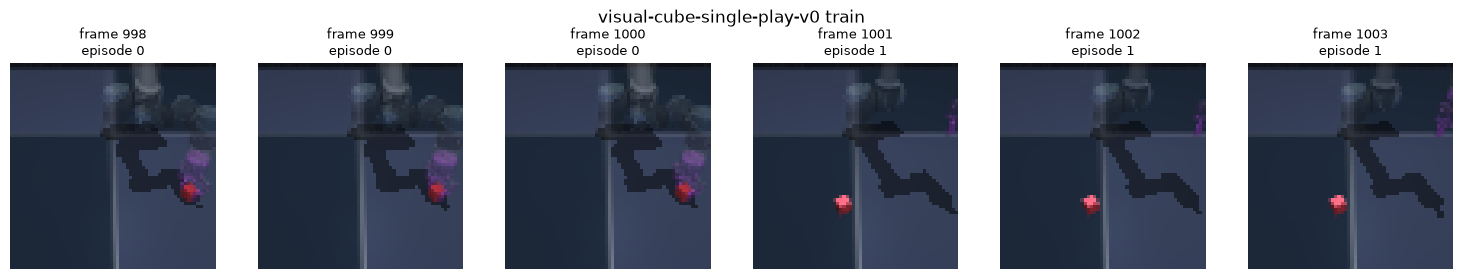

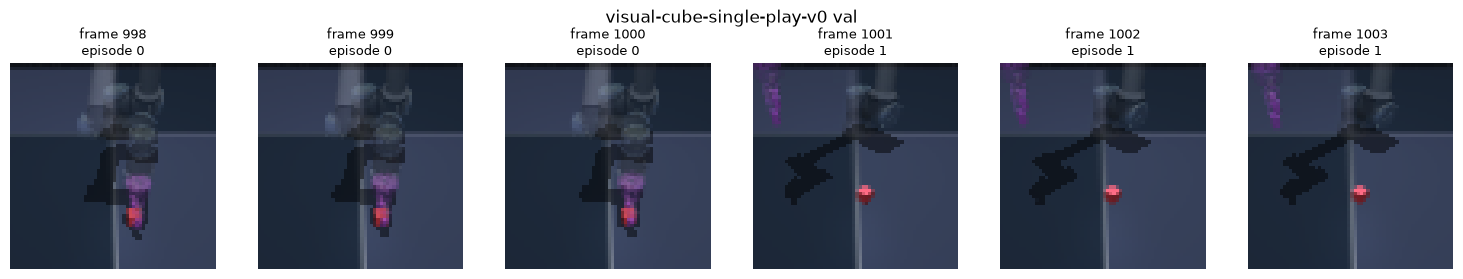

In [6]:
show_preview(train_dataset, title=f"{DATASET_NAME} train")
show_preview(val_dataset, title=f"{DATASET_NAME} val")

In [7]:
def modify_dataset(dataset: dict, mode: str = "baseline", seed: int = 0) -> dict:
    if mode == "baseline":
        return dataset
    rng = np.random.default_rng(seed)
    episodes = episode_ids(dataset)
    if mode == "episode":
        # slow feature
        colors = rng.integers(0, 256, size=(episodes[-1] + 1, 3), dtype=np.uint8)[episodes]
    elif mode == "frame":
        # fast feature control
        colors = rng.integers(0, 256, size=(len(episodes), 3), dtype=np.uint8)
    else:
        raise ValueError(f"Invalid mode: {mode}")
    return {**dataset, "square_colors": colors}

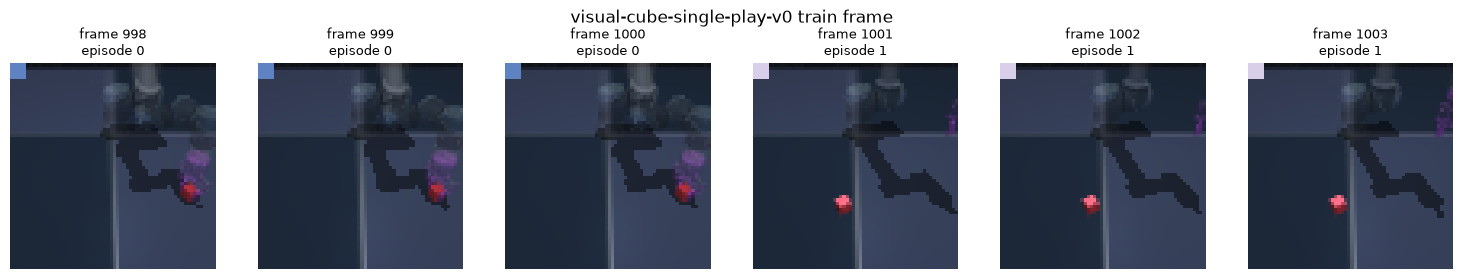

In [9]:
show_preview(modify_dataset(train_dataset, mode="episode"), title=f"{DATASET_NAME} train frame")